In [1]:
print("Hello")

Hello


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("house-prices-advanced-regression-techniques/train.csv")

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
df.shape


(1460, 81)

In [6]:
from email import errors
from os import error


df=df.drop(columns=['Id'],errors='ignore')


In [7]:
df.head(2)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500


In [8]:
missing_values=df.isnull().sum()
missing_values=missing_values[missing_values>0].sort_values(ascending=False)
missing_values


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [9]:
missing_percentage=df.isnull().mean()
thresold=0.65
missing_percentage=missing_percentage[missing_percentage >thresold].index.to_list()
missing_percentage

['Alley', 'PoolQC', 'Fence', 'MiscFeature']

In [10]:
df=df.drop(columns=missing_percentage,errors='ignore')
df.shape

(1460, 76)

In [11]:
import numpy as np

In [12]:
# Filter by importance
# (Correlation with salePrice)

target_coorelation = df.select_dtypes(include=[np.number]).corr()['SalePrice'].abs()

In [13]:
target_coorelation

MSSubClass       0.084284
LotFrontage      0.351799
LotArea          0.263843
OverallQual      0.790982
OverallCond      0.077856
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.477493
BsmtFinSF1       0.386420
BsmtFinSF2       0.011378
BsmtUnfSF        0.214479
TotalBsmtSF      0.613581
1stFlrSF         0.605852
2ndFlrSF         0.319334
LowQualFinSF     0.025606
GrLivArea        0.708624
BsmtFullBath     0.227122
BsmtHalfBath     0.016844
FullBath         0.560664
HalfBath         0.284108
BedroomAbvGr     0.168213
KitchenAbvGr     0.135907
TotRmsAbvGrd     0.533723
Fireplaces       0.466929
GarageYrBlt      0.486362
GarageCars       0.640409
GarageArea       0.623431
WoodDeckSF       0.324413
OpenPorchSF      0.315856
EnclosedPorch    0.128578
3SsnPorch        0.044584
ScreenPorch      0.111447
PoolArea         0.092404
MiscVal          0.021190
MoSold           0.046432
YrSold           0.028923
SalePrice        1.000000
Name: SalePrice, dtype: float64

In [14]:
low_imapct_threshold = 0.1

# Interview Question : coorelation vs covariance
# Always use coorelation

low_impact_cols = target_coorelation[target_coorelation<low_imapct_threshold].index.to_list()
low_impact_cols

['MSSubClass',
 'OverallCond',
 'BsmtFinSF2',
 'LowQualFinSF',
 'BsmtHalfBath',
 '3SsnPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold']

In [15]:
df_2 = df.drop(columns=low_impact_cols, errors='ignore')
df_2.shape

(1460, 66)

In [16]:
# Removing multi-collinearity

corr_matrix = df.select_dtypes(include=[np.number]).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
redundant_cols = [column for column in upper.columns if any(upper[column] > 0.8)]
print(redundant_cols)

['1stFlrSF', 'TotRmsAbvGrd', 'GarageYrBlt', 'GarageArea']


In [17]:
df3=df_2.drop(columns=redundant_cols,errors='ignore')
df3.shape

(1460, 62)

In [18]:
missing_values2=df3.isnull().sum()
missing_values2=missing_values2[missing_values2 >0 ].sort_values(ascending=False)
missing_values2

MasVnrType      872
FireplaceQu     690
LotFrontage     259
GarageType       81
GarageQual       81
GarageFinish     81
GarageCond       81
BsmtFinType2     38
BsmtExposure     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrArea        8
Electrical        1
dtype: int64

In [19]:
df_mean=df3.copy()
df_mean.fillna({"LotFrontage": df3['LotFrontage'].mean()},inplace=True)

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,61,0,0,WD,Normal,208500
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298,0,0,0,WD,Normal,181500
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,42,0,0,WD,Normal,223500
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0,35,272,0,WD,Abnorml,140000
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192,84,0,0,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917,Pave,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,TA,TA,Y,0,40,0,0,WD,Normal,175000
1456,RL,85.0,13175,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,TA,TA,Y,349,0,0,0,WD,Normal,210000
1457,RL,66.0,9042,Pave,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,TA,TA,Y,0,60,0,0,WD,Normal,266500
1458,RL,68.0,9717,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,TA,TA,Y,366,0,112,0,WD,Normal,142125


In [20]:
missing_values=df_mean.isnull().sum()
missing_values=missing_values[missing_values>0].sort_values(ascending=False)
missing_values

MasVnrType      872
FireplaceQu     690
GarageType       81
GarageQual       81
GarageFinish     81
GarageCond       81
BsmtFinType2     38
BsmtExposure     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrArea        8
Electrical        1
dtype: int64

In [21]:
df_median=df3.copy()
df_median.fillna({"LotFrontage": df3['LotFrontage'].median()},inplace=True)

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,61,0,0,WD,Normal,208500
1,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298,0,0,0,WD,Normal,181500
2,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0,42,0,0,WD,Normal,223500
3,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0,35,272,0,WD,Abnorml,140000
4,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192,84,0,0,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917,Pave,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,TA,TA,Y,0,40,0,0,WD,Normal,175000
1456,RL,85.0,13175,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,TA,TA,Y,349,0,0,0,WD,Normal,210000
1457,RL,66.0,9042,Pave,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,TA,TA,Y,0,60,0,0,WD,Normal,266500
1458,RL,68.0,9717,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,TA,TA,Y,366,0,112,0,WD,Normal,142125


In [22]:
df3['GarageType'].unique()

<StringArray>
['Attchd', 'Detchd', 'BuiltIn', 'CarPort', nan, 'Basment', '2Types']
Length: 7, dtype: str

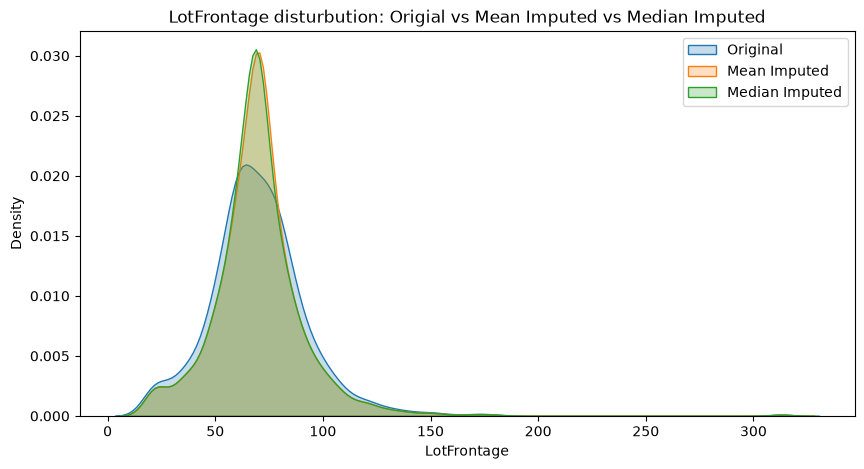

In [23]:
plt.figure(figsize=(10,5))
sns.kdeplot(df["LotFrontage"],label="Original",fill=True)
sns.kdeplot(df_mean["LotFrontage"],label="Mean Imputed",fill=True)
sns.kdeplot(df_median["LotFrontage"],label="Median Imputed",fill=True)
plt.legend()
plt.title("LotFrontage disturbution: Origial vs Mean Imputed vs Median Imputed")
plt.show()

In [24]:
from sklearn.impute import KNNImputer

In [25]:
df_knn=df3.copy()

In [26]:
knnimputer=KNNImputer(n_neighbors=4)

In [27]:
numerical_cols=df_knn.select_dtypes(include=[np.number]).columns
numerical_cols

Index(['LotFrontage', 'LotArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd',
       'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', '2ndFlrSF',
       'GrLivArea', 'BsmtFullBath', 'FullBath', 'HalfBath', 'BedroomAbvGr',
       'KitchenAbvGr', 'Fireplaces', 'GarageCars', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', 'ScreenPorch', 'SalePrice'],
      dtype='str')

In [28]:
df_knn[numerical_cols]=knnimputer.fit_transform(df_knn[numerical_cols])

In [29]:
null_values=df_knn[numerical_cols].isna().sum().sort_values(ascending=False)
null_values

LotFrontage      0
LotArea          0
OverallQual      0
YearBuilt        0
YearRemodAdd     0
MasVnrArea       0
BsmtFinSF1       0
BsmtUnfSF        0
TotalBsmtSF      0
2ndFlrSF         0
GrLivArea        0
BsmtFullBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
Fireplaces       0
GarageCars       0
WoodDeckSF       0
OpenPorchSF      0
EnclosedPorch    0
ScreenPorch      0
SalePrice        0
dtype: int64

In [30]:
df_knn

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
0,RL,65.0,8450.0,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0.0,61.0,0.0,0.0,WD,Normal,208500.0
1,RL,80.0,9600.0,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,TA,TA,Y,298.0,0.0,0.0,0.0,WD,Normal,181500.0
2,RL,68.0,11250.0,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,TA,TA,Y,0.0,42.0,0.0,0.0,WD,Normal,223500.0
3,RL,60.0,9550.0,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,TA,TA,Y,0.0,35.0,272.0,0.0,WD,Abnorml,140000.0
4,RL,84.0,14260.0,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,TA,TA,Y,192.0,84.0,0.0,0.0,WD,Normal,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,62.0,7917.0,Pave,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,...,TA,TA,Y,0.0,40.0,0.0,0.0,WD,Normal,175000.0
1456,RL,85.0,13175.0,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,TA,TA,Y,349.0,0.0,0.0,0.0,WD,Normal,210000.0
1457,RL,66.0,9042.0,Pave,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,TA,TA,Y,0.0,60.0,0.0,0.0,WD,Normal,266500.0
1458,RL,68.0,9717.0,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,TA,TA,Y,366.0,0.0,112.0,0.0,WD,Normal,142125.0


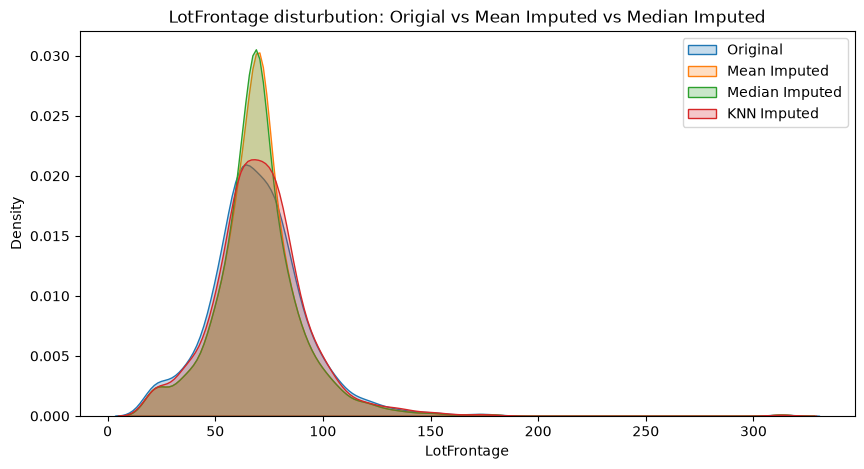

In [31]:
plt.figure(figsize=(10,5))
sns.kdeplot(df["LotFrontage"],label="Original",fill=True)
sns.kdeplot(df_mean["LotFrontage"],label="Mean Imputed",fill=True)
sns.kdeplot(df_median["LotFrontage"],label="Median Imputed",fill=True)
sns.kdeplot(df_knn["LotFrontage"],label="KNN Imputed",fill=True)
plt.legend()
plt.title("LotFrontage disturbution: Origial vs Mean Imputed vs Median Imputed")
plt.show()

In [32]:
from sklearn.linear_model import LinearRegression

In [33]:
df_reg=df3.copy()
train_data=df_reg.dropna(subset=["LotFrontage"])
test_data=df_reg[df_reg["LotFrontage"].isnull()]

In [34]:
target_coorelation_ml=df_reg.select_dtypes(include=[np.number]).corr()['LotFrontage'].abs().sort_values(ascending=False)
target_coorelation_ml

LotFrontage      1.000000
LotArea          0.426095
GrLivArea        0.402797
TotalBsmtSF      0.392075
SalePrice        0.351799
GarageCars       0.285691
Fireplaces       0.266639
BedroomAbvGr     0.263170
OverallQual      0.251646
BsmtFinSF1       0.233633
FullBath         0.198769
MasVnrArea       0.193458
OpenPorchSF      0.151972
BsmtUnfSF        0.132644
YearBuilt        0.123349
BsmtFullBath     0.100949
YearRemodAdd     0.088866
WoodDeckSF       0.088521
2ndFlrSF         0.080177
HalfBath         0.053532
ScreenPorch      0.041383
EnclosedPorch    0.010700
KitchenAbvGr     0.006069
Name: LotFrontage, dtype: float64

In [35]:
train_data.info()

<class 'pandas.DataFrame'>
Index: 1201 entries, 0 to 1459
Data columns (total 62 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSZoning       1201 non-null   str    
 1   LotFrontage    1201 non-null   float64
 2   LotArea        1201 non-null   int64  
 3   Street         1201 non-null   str    
 4   LotShape       1201 non-null   str    
 5   LandContour    1201 non-null   str    
 6   Utilities      1201 non-null   str    
 7   LotConfig      1201 non-null   str    
 8   LandSlope      1201 non-null   str    
 9   Neighborhood   1201 non-null   str    
 10  Condition1     1201 non-null   str    
 11  Condition2     1201 non-null   str    
 12  BldgType       1201 non-null   str    
 13  HouseStyle     1201 non-null   str    
 14  OverallQual    1201 non-null   int64  
 15  YearBuilt      1201 non-null   int64  
 16  YearRemodAdd   1201 non-null   int64  
 17  RoofStyle      1201 non-null   str    
 18  RoofMatl       1201 non-

In [36]:
X_train=train_data[["LotArea", "OverallQual", "TotalBsmtSF", "GrLivArea"]]
Y_train=train_data["LotFrontage"]

In [37]:
reg=LinearRegression()

In [38]:
reg.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0. ,-1.5 , 0.01, 0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['LotArea','OverallQual','TotalBsmtSF','GrLivArea']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,39.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [39]:
reg.coef_

array([ 8.90135199e-04, -1.49550808e+00,  1.24430130e-02,  1.16904327e-02])

In [40]:
test_data.head()

,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,SaleType,SaleCondition,SalePrice
7,RL,NaN,10382,Pave,IR1,Lvl,AllPub,Corner,Gtl,NWAmes,...,TA,TA,Y,235,204,228,0,WD,Normal,200000
12,RL,NaN,12968,Pave,IR2,Lvl,AllPub,Inside,Gtl,Sawyer,...,TA,TA,Y,140,0,0,176,WD,Normal,144000
14,RL,NaN,10920,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,TA,TA,Y,0,213,176,0,WD,Normal,157000
16,RL,NaN,11241,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,NAmes,...,TA,TA,Y,0,0,0,0,WD,Normal,149000
24,RL,NaN,8246,Pave,IR1,Lvl,AllPub,Inside,Gtl,Sawyer,...,TA,TA,Y,406,90,0,0,WD,Normal,154000


In [41]:
df_reg.loc[df_reg["LotFrontage"].isnull(),"Lotfrontage"]=reg.predict(test_data[["LotArea", "OverallQual", "TotalBsmtSF", "GrLivArea"]])

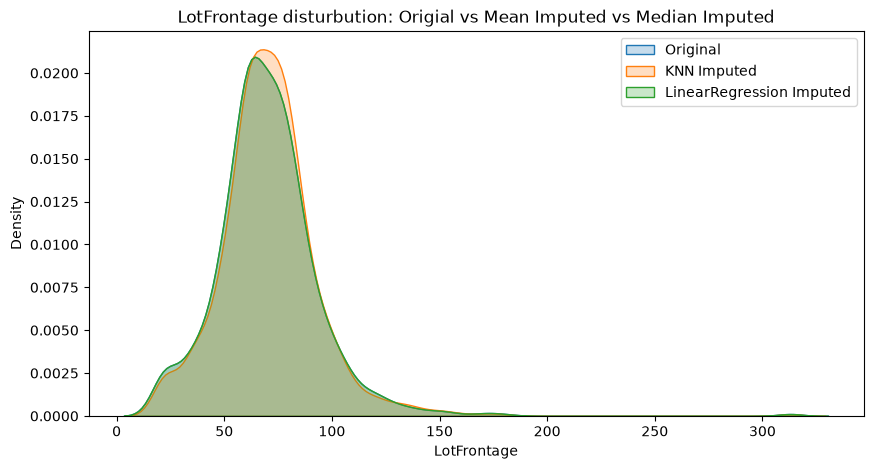

In [42]:
plt.figure(figsize=(10,5))
sns.kdeplot(df["LotFrontage"],label="Original",fill=True)
# sns.kdeplot(df_mean["LotFrontage"],label="Mean Imputed",fill=True)
# sns.kdeplot(df_median["LotFrontage"],label="Median Imputed",fill=True)
sns.kdeplot(df_knn["LotFrontage"],label="KNN Imputed",fill=True)
sns.kdeplot(df_reg["LotFrontage"], label="LinearRegression Imputed", fill=True)
plt.legend()
plt.title("LotFrontage disturbution: Origial vs Mean Imputed vs Median Imputed")
plt.show()

In [43]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression

In [44]:
df=pd.read_csv("house-prices-advanced-regression-techniques/train.csv")

In [45]:
cols_to_use = ["LotFrontage", "LotArea", "OverallQual", "OverallCond", "1stFlrSF", "GrLivArea", "GarageYrBlt", "MasVnrArea"]

In [46]:
df[cols_to_use].info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   LotFrontage  1201 non-null   float64
 1   LotArea      1460 non-null   int64  
 2   OverallQual  1460 non-null   int64  
 3   OverallCond  1460 non-null   int64  
 4   1stFlrSF     1460 non-null   int64  
 5   GrLivArea    1460 non-null   int64  
 6   GarageYrBlt  1379 non-null   float64
 7   MasVnrArea   1452 non-null   float64
dtypes: float64(3), int64(5)
memory usage: 91.4 KB


In [47]:
df_subset=df[cols_to_use].copy()

In [48]:
iter_input=IterativeImputer(estimator=LinearRegression(),max_iter=10,random_state=10)

In [49]:
df_subset_imputed_values=iter_input.fit_transform(df_subset)

In [50]:
df_subset[cols_to_use]=df_subset_imputed_values
df_subset.info 

<bound method DataFrame.info of       LotFrontage  LotArea  OverallQual  OverallCond  1stFlrSF  GrLivArea  \
0            65.0   8450.0          7.0          5.0     856.0     1710.0   
1            80.0   9600.0          6.0          8.0    1262.0     1262.0   
2            68.0  11250.0          7.0          5.0     920.0     1786.0   
3            60.0   9550.0          7.0          5.0     961.0     1717.0   
4            84.0  14260.0          8.0          5.0    1145.0     2198.0   
...           ...      ...          ...          ...       ...        ...   
1455         62.0   7917.0          6.0          5.0     953.0     1647.0   
1456         85.0  13175.0          6.0          6.0    2073.0     2073.0   
1457         66.0   9042.0          7.0          9.0    1188.0     2340.0   
1458         68.0   9717.0          5.0          6.0    1078.0     1078.0   
1459         75.0   9937.0          5.0          6.0    1256.0     1256.0   

      GarageYrBlt  MasVnrArea  
0          

#outliers


In [51]:
df=pd.read_csv("house-prices-advanced-regression-techniques/train.csv")

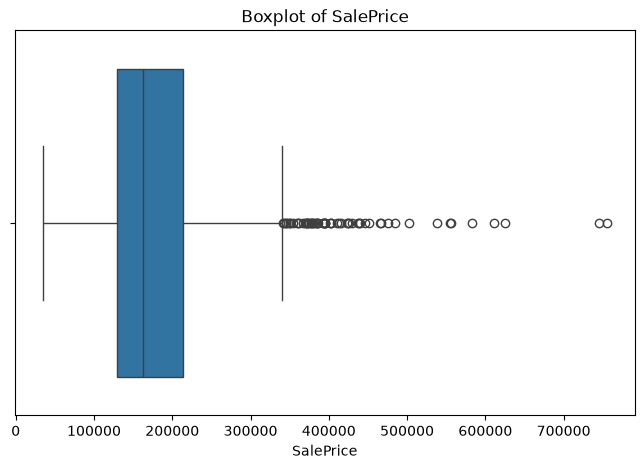

In [52]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["SalePrice"])
plt.title("Boxplot of SalePrice")
plt.show()

In [53]:
import numpy as np

In [54]:
df=pd.read_csv("house-prices-advanced-regression-techniques/train.csv")

In [55]:
def detect_outliers(data,col):
    Q1=data[col].quantile(0.25)
    Q3=data[col].quantile(0.75)

    IQR=Q3-Q1
    lower_fence=Q1-1.5*IQR
    upper_fence=Q3+1.5*IQR

    outliers=data[(data[col]<lower_fence) | (data[col]>upper_fence)]
    return outliers[[col]]

In [56]:
outliers_saleprice=detect_outliers(df,"SalePrice")

In [57]:
print(f"No. of outliers in SalePrice : {len(outliers_saleprice)}")
display(outliers_saleprice.head())

No. of outliers in SalePrice : 61


,SalePrice
11,345000
53,385000
58,438780
112,383970
151,372402


In [58]:
import scipy.stats as stats

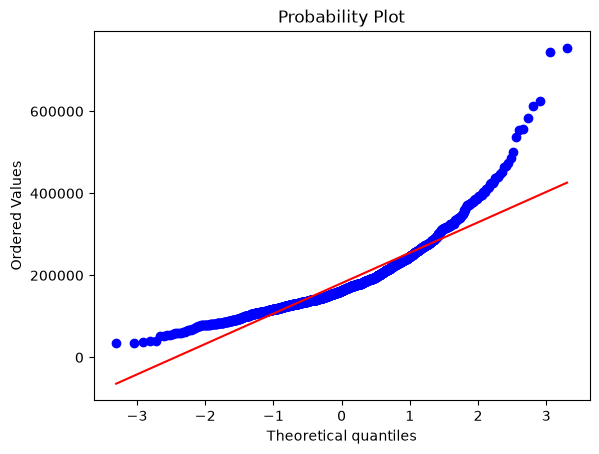

In [59]:
stats.probplot(df['SalePrice'],dist='norm',plot=plt)
plt.show()

In [60]:
#Feature Scaling

from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,PowerTransformer

In [61]:
def summary_stats(series):
    return {
        "mean":series.mean(),
        "std":series.std(),
        "skewness":series.skew()
    }

In [62]:
def compare_disturbutions(original,transformed,title):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    sns.histplot(original,bins=30,kde=True,ax=axes[0])
    axes[0].set_title(f"{title}-Before")
    sns.histplot(transformed,bins=30,kde=True,ax=axes[1])
    axes[1].set_title(f"{title}-After")
    plt.show()




In [63]:
col='LotFrontage'
scaler=StandardScaler()
lot_scaled=scaler.fit_transform(df[[col]])
print("before:= ",summary_stats(df[[col]].dropna()))
print("After:==",summary_stats(pd.Series(lot_scaled.flatten())))

before:=  {'mean': LotFrontage    70.049958
dtype: float64, 'std': LotFrontage    24.284752
dtype: float64, 'skewness': LotFrontage    2.163569
dtype: float64}
After:== {'mean': np.float64(-2.677107310003708e-16), 'std': np.float64(1.0004165798972613), 'skewness': np.float64(2.163569142324884)}


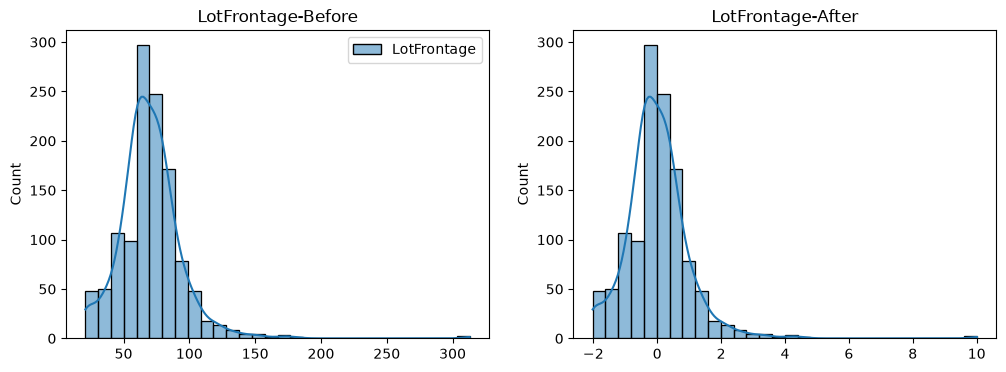

In [64]:
compare_disturbutions(df[[col]],pd.Series(lot_scaled.flatten()),col)

before:=  {'mean': LotFrontage    70.049958
dtype: float64, 'std': LotFrontage    24.284752
dtype: float64, 'skewness': LotFrontage    2.163569
dtype: float64}
After:== {'mean': np.float64(0.1679793094795433), 'std': np.float64(0.0831669581317918), 'skewness': np.float64(2.1635691423248855)}


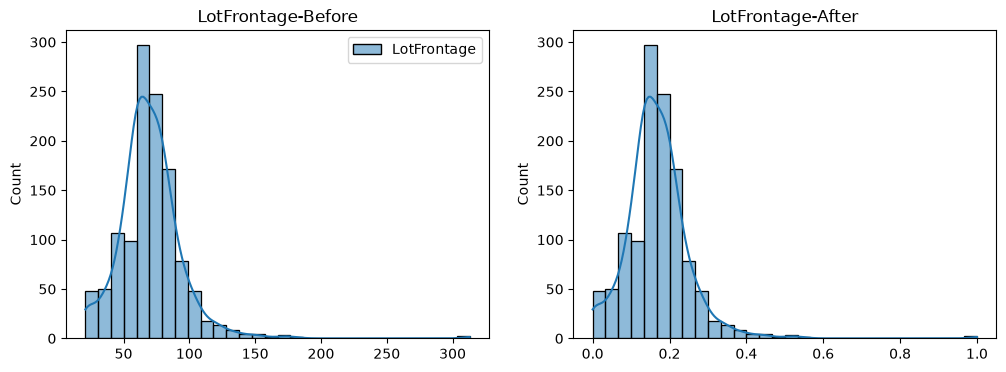

In [65]:
col='LotFrontage'
scaler=MinMaxScaler()
lot_scaled=scaler.fit_transform(df[[col]])
print("before:= ",summary_stats(df[[col]].dropna()))
print("After:==",summary_stats(pd.Series(lot_scaled.flatten())))
compare_disturbutions(df[[col]],pd.Series(lot_scaled.flatten()),col)

before:=  {'mean': LotFrontage    70.049958
dtype: float64, 'std': LotFrontage    24.284752
dtype: float64, 'skewness': LotFrontage    2.163569
dtype: float64}
After:== {'mean': np.float64(0.04999801752507831), 'std': np.float64(1.156416751165867), 'skewness': np.float64(2.163569142324882)}


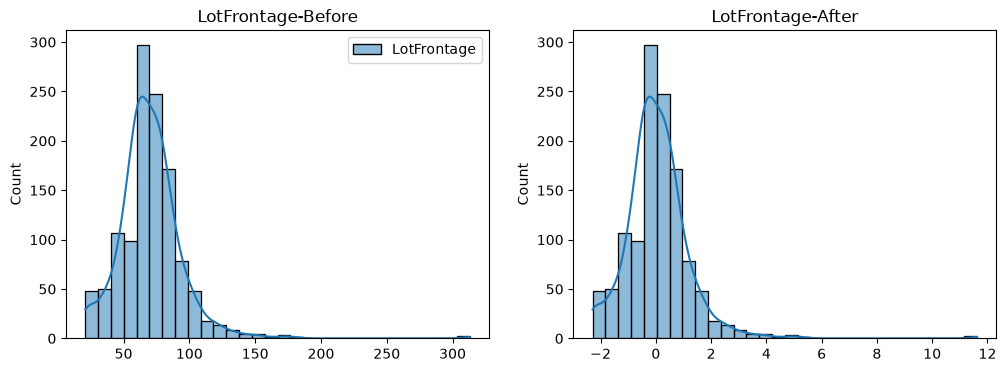

In [66]:
col='LotFrontage'
scaler=RobustScaler()
lot_scaled=scaler.fit_transform(df[[col]])
print("before:= ",summary_stats(df[[col]].dropna()))
print("After:==",summary_stats(pd.Series(lot_scaled.flatten())))
compare_disturbutions(df[[col]],pd.Series(lot_scaled.flatten()),col)

before:=  {'mean': LotFrontage    70.049958
dtype: float64, 'std': LotFrontage    24.284752
dtype: float64, 'skewness': LotFrontage    2.163569
dtype: float64}
After:== {'mean': LotFrontage    4.207109
dtype: float64, 'std': LotFrontage    0.346228
dtype: float64, 'skewness': LotFrontage   -0.728728
dtype: float64}


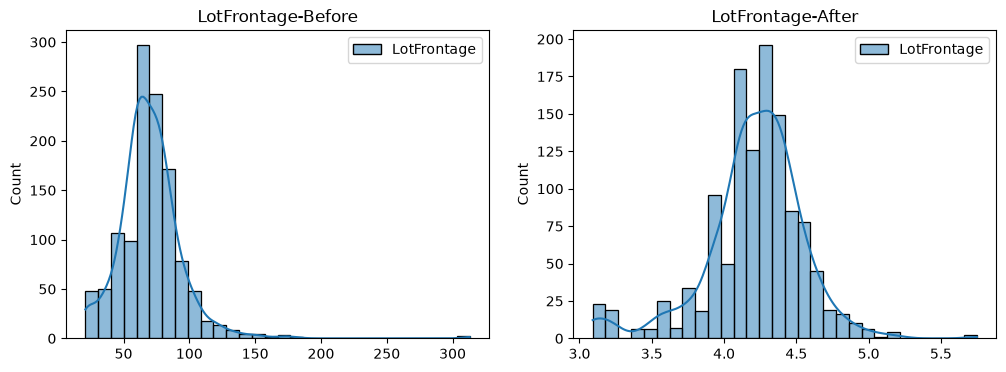

In [67]:
col='LotFrontage'
log_tranform=np.log1p(df[[col]])
lot_scaled=scaler.fit_transform(df[[col]])
print("before:= ",summary_stats(df[[col]].dropna()))
print("After:==",summary_stats(log_tranform))
compare_disturbutions(df[[col]],log_tranform,col)

In [68]:
from sklearn.preprocessing import LabelEncoder

In [71]:
col='MSZoning'
print("Before",df[col].unique())

Before <StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str


In [72]:
df['MSZoning_label']=pd.factorize(df[col])[0]

le=LabelEncoder()
df['MSZoning_sklearn']=le.fit_transform(df[col])

print("After Pandas factorization",df['MSZoning_label'].unique())
print("After Sklearn encoding",df['MSZoning_sklearn'].unique())

After Pandas factorization [0 1 2 3 4]
After Sklearn encoding [3 4 0 1 2]


In [73]:
from sklearn.preprocessing import OrdinalEncoder

In [76]:
ordinal_order=[['C (all)','RL', 'RM', 'FV', 'RH']]
oe=OrdinalEncoder()
df["MSZoning_ordinal"]=oe.fit_transform(df[['MSZoning']])
print("After ordinal ",df['MSZoning_ordinal'].unique())

After ordinal  [3. 4. 0. 1. 2.]


In [80]:
#one hotEncoding

col='MSZoning'

mszoning_ohe_pandas=pd.get_dummies(df[col],prefix='MSZoning')

pandas_comparison=pd.concat([df[col],mszoning_ohe_pandas],axis=1)

unique_pandas_ohe=pandas_comparison.drop_duplicates(subset=[col]).reset_index(drop=True)

In [81]:
unique_pandas_ohe

,MSZoning,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM
0,RL,False,False,False,True,False
1,RM,False,False,False,False,True
2,C (all),True,False,False,False,False
3,FV,False,True,False,False,False
4,RH,False,False,True,False,False


In [82]:
from sklearn.preprocessing import OneHotEncoder

ohe=OneHotEncoder(sparse_output=False,drop=None)

mszoning_ohe_sklearn=ohe.fit_transform(df[[col]])

ohe_df=pd.DataFrame(mszoning_ohe_sklearn,columns=ohe.get_feature_names_out([col]))

sklearn_comparsion=pd.concat([df[col],ohe_df],axis=1)

unique_sklearn_ohe_df=sklearn_comparsion.drop_duplicates(subset=[col]).reset_index(drop=True)


unique_sklearn_ohe_df

,MSZoning,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM
0,RL,0.0,0.0,0.0,1.0,0.0
1,RM,0.0,0.0,0.0,0.0,1.0
2,C (all),1.0,0.0,0.0,0.0,0.0
3,FV,0.0,1.0,0.0,0.0,0.0
4,RH,0.0,0.0,1.0,0.0,0.0
